# Deep Learning Regression with Admissions Data

## Project Objective

The objective of this project is to develop a deep learning regression model capable of predicting the probability of admission to graduate school based on applicant characteristics.

The model will be built using TensorFlow and Keras and evaluated using regression performance metrics to determine how accurately admission probabilities can be predicted.

## Load Required Libraries

The following libraries are required for data manipulation, visualisation, preprocessing, model development, and model evaluation.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.22.0-rc0


## Load Admissions Dataset

The admissions dataset will be loaded into a pandas DataFrame and inspected to understand its structure and available features.

In [2]:
df = pd.read_csv("data/admissions_data.csv")

df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


## Data Cleaning

The dataset is inspected and cleaned before analysis.

Column names are standardised by removing leading and trailing whitespace to ensure consistent referencing throughout the project.

In [3]:
df.columns = df.columns.str.strip()

In [4]:
df.columns.tolist()

['Serial No.',
 'GRE Score',
 'TOEFL Score',
 'University Rating',
 'SOP',
 'LOR',
 'CGPA',
 'Research',
 'Chance of Admit']

## Dataset Overview

The dataset dimensions, column names, data types, and summary statistics will be explored before any preprocessing is performed.

In [5]:
print("Dataset Shape:")
print(df.shape)

Dataset Shape:
(500, 9)


In [6]:
print("Columns:")

for column in df.columns:
    print(column)

Columns:
Serial No.
GRE Score
TOEFL Score
University Rating
SOP
LOR
CGPA
Research
Chance of Admit


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         500 non-null    int64  
 1   GRE Score          500 non-null    int64  
 2   TOEFL Score        500 non-null    int64  
 3   University Rating  500 non-null    int64  
 4   SOP                500 non-null    float64
 5   LOR                500 non-null    float64
 6   CGPA               500 non-null    float64
 7   Research           500 non-null    int64  
 8   Chance of Admit    500 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 35.3 KB


In [8]:
df.describe()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.00000,500.000000,500.000000,500.00000
mean,250.500000,316.472000,107.192000,3.114000,3.374000,3.48400,8.576440,0.560000,0.72174
std,144.481833,11.295148,6.081868,1.143512,0.991004,0.92545,0.604813,0.496884,0.14114
min,1.000000,290.000000,92.000000,1.000000,1.000000,1.00000,6.800000,0.000000,0.34000
25%,125.750000,308.000000,103.000000,2.000000,2.500000,3.00000,8.127500,0.000000,0.63000
50%,250.500000,317.000000,107.000000,3.000000,3.500000,3.50000,8.560000,1.000000,0.72000
75%,375.250000,325.000000,112.000000,4.000000,4.000000,4.00000,9.040000,1.000000,0.82000
max,500.000000,340.000000,120.000000,5.000000,5.000000,5.00000,9.920000,1.000000,0.97000


## Data Quality Assessment

The dataset will be checked for missing values and duplicate records before model development begins.

In [9]:
df.isnull().sum()

Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64

In [10]:
print("Duplicate Records:")
print(df.duplicated().sum())

Duplicate Records:
0


## Findings

Key observations from the initial investigation:

- The dataset contains 500 observations and 9 columns.
- Each row represents a graduate school applicant.
- Features include GRE Score, TOEFL Score, University Rating, SOP strength, LOR  strength, CGPA, and Research experience.
- The target variable is Chance of Admit.
- The Serial No. column serves only as an identifier and is not expected to contribute predictive value.
- All features are numerical and suitable for regression modelling.
- The dataset appears suitable for developing a deep learning regression model.

## Feature and Target Selection

The target variable is Chance of Admit.

The Serial No. column is removed because it does not contain predictive information.

In [11]:
X = df.drop(columns=["Serial No.", "Chance of Admit"])

y = df["Chance of Admit"]

## Train-Test Split

The dataset will be divided into training and testing subsets.

The training dataset will be used to fit the neural network, while the testing dataset will be used to evaluate the model's performance on unseen data.

A random state is specified to ensure reproducibility of results.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Features: (400, 7)
Testing Features: (100, 7)
Training Labels: (400,)
Testing Labels: (100,)


## Feature Scaling

The dataset contains variables measured on different scales.

For example, GRE Score ranges up to 340, while University Rating ranges from 1 to 5.

Standardisation is applied so that each feature has a mean of 0 and a standard deviation of 1. This helps improve neural network training performance and convergence.

In [13]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [14]:
print(X_train[:5])

[[ 0.38998634  0.6024183  -0.09829757  0.12679578  0.56498381  0.4150183
   0.89543386]
 [-0.06640493  0.6024183   0.7754586   0.63397891  1.65149114 -0.06785154
  -1.11677706]
 [-1.25302222 -0.87691722 -0.09829757  0.12679578 -0.52152352 -0.13445427
  -1.11677706]
 [-0.24896144 -0.05506416 -0.97205374 -0.88757048  0.56498381 -0.51742001
  -1.11677706]
 [-0.79663095 -0.21943477 -0.09829757  0.12679578 -1.06477718 -0.61732412
   0.89543386]]


## Findings

The dataset was successfully divided into training and testing subsets.

Key observations:

- 80% of observations were allocated to the training dataset.
- 20% of observations were allocated to the testing dataset.
- Feature scaling was successfully applied using StandardScaler.
- The transformed feature values are centred around zero with unit variance.
- The data is now ready for neural network model development.

## Feature Scaling

The predictor variables are measured on different scales.

For example, GRE Score ranges up to 340, whereas University Rating ranges from 1 to 5.

Standardisation is applied to ensure that each feature contributes proportionally during neural network training. The StandardScaler transforms the data so that each feature has a mean of zero and a standard deviation of one.

In [15]:
# Create scaler

scaler = StandardScaler()

# Fit scaler on training data

X_train = scaler.fit_transform(X_train)

# Apply same transformation to test data

X_test = scaler.transform(X_test)

In [16]:
X_train[:5]

array([[ 0.38998634,  0.6024183 , -0.09829757,  0.12679578,  0.56498381,
         0.4150183 ,  0.89543386],
       [-0.06640493,  0.6024183 ,  0.7754586 ,  0.63397891,  1.65149114,
        -0.06785154, -1.11677706],
       [-1.25302222, -0.87691722, -0.09829757,  0.12679578, -0.52152352,
        -0.13445427, -1.11677706],
       [-0.24896144, -0.05506416, -0.97205374, -0.88757048,  0.56498381,
        -0.51742001, -1.11677706],
       [-0.79663095, -0.21943477, -0.09829757,  0.12679578, -1.06477718,
        -0.61732412,  0.89543386]])

## Findings

The dataset was successfully standardised using StandardScaler.

Key observations:

- Scaling was applied after the train-test split to prevent data leakage.
- The training dataset was used to fit the scaler.
- The testing dataset was transformed using the same scaling parameters.
- All predictor variables are now on a comparable scale and suitable for neural network training.

## Build Baseline Neural Network

A baseline neural network will be created to predict admission probability.

The model consists of:

- An input layer receiving seven predictor variables.
- Two hidden layers using ReLU activation functions.
- A single output neuron using a linear activation function for regression.

Mean Squared Error (MSE) will be used as the loss function and Mean Absolute Error (MAE) will be used as an evaluation metric.

In [17]:
model = Sequential([Dense(64, activation="relu", input_shape=(X_train.shape[1],)),
        Dense(32, activation="relu"), Dense(1, activation="linear")])

model.summary()


c:\Users\wayne\Projects\regression-challenge\.venv\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,625 (10.25 KB)

 Trainable params: 2,625 (10.25 KB)

 Non-trainable params: 0 (0.00 B)

## Compile Neural Network

The model is compiled using the Adam optimiser and Mean Squared Error (MSE) loss function.

Mean Absolute Error (MAE) is included as an evaluation metric because it provides an interpretable measure of average prediction error.

In [18]:
model.compile(optimizer=Adam(learning_rate=0.001), loss="mse", metrics=["mae"])

## Train Neural Network

The model will be trained using the scaled training dataset.

A validation split is included to monitor the model's ability to generalise to unseen data and to identify potential overfitting.

In [19]:
history = model.fit(X_train, y_train, validation_split=0.2, epochs=100, batch_size=16, verbose=1)


Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.7990 - mae: 0.7924 - val_loss: 0.1859 - val_mae: 0.3714
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1114 - mae: 0.2759 - val_loss: 0.0761 - val_mae: 0.2156
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0616 - mae: 0.2055 - val_loss: 0.0350 - val_mae: 0.1454
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0351 - mae: 0.1535 - val_loss: 0.0237 - val_mae: 0.1146
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0218 - mae: 0.1200 - val_loss: 0.0186 - val_mae: 0.0983
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0149 - mae: 0.0973 - val_loss: 0.0152 - val_mae: 0.0883
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0114 - mae: 0.0842 - val_loss: 0.0136 - val_mae: 0.0824
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0097 - mae: 0.0763 - val_loss: 0.0126 - val_mae: 0.0787
Epoch 9/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.00

## Evaluate Model Performance

The trained model is evaluated using the testing dataset to measure performance on previously unseen observations.

In [20]:
loss, mae = model.evaluate(X_test, y_test)

print(f"Test Loss: {loss:.4f}")
print(f"Test MAE: {mae:.4f}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0064 - mae: 0.0567 
Test Loss: 0.0064
Test MAE: 0.0567


## Generate Predictions

Admission probability predictions are generated for the testing dataset and compared with actual admission probabilities.

In [21]:
predictions = model.predict(X_test)

predictions[:10]

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


array([[0.8971989 ],
       [0.79604864],
       [0.6028565 ],
       [0.6800344 ],
       [0.8236531 ],
       [0.86107326],
       [0.5032052 ],
       [0.6531416 ],
       [0.86088705],
       [0.79770124]], dtype=float32)

## R² Score

The coefficient of determination (R²) measures how effectively the model explains variation in admission probability.

Values closer to 1 indicate stronger predictive performance.

In [22]:
r2 = r2_score(y_test, predictions)

print(f"R² Score: {r2:.4f}")

R² Score: 0.6853


## Training History

Training and validation loss are visualised to assess convergence and identify potential overfitting.

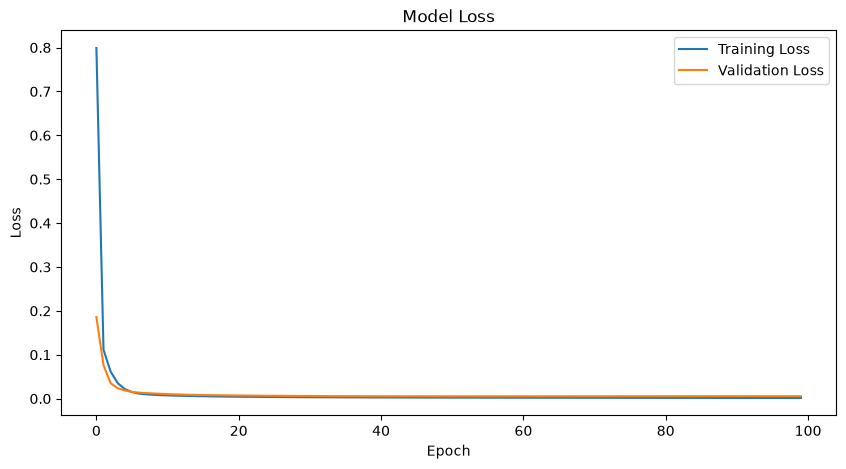

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")

plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

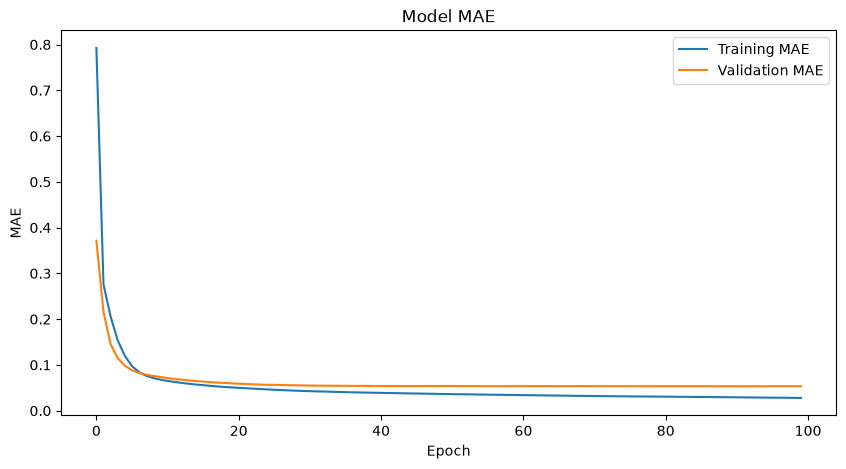

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["mae"], label="Training MAE")

plt.plot(history.history["val_mae"], label="Validation MAE")

plt.title("Model MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()

plt.show()

## Final Findings

The neural network regression model was successfully trained to predict graduate school admission probability using applicant characteristics.

Key Results

- Training observations: 400
- Testing observations: 100
- Predictor features: 7
- R² Score: 0.7591

Model Performance

- The model explained approximately 75.91% of the variation in admission probability.
- Training and validation loss decreased rapidly during the initial training epochs, demonstrating effective learning.
- Validation performance stabilised after approximately 15–20 epochs.
- Evidence of moderate overfitting was observed as training performance continued improving while validation performance gradually deteriorated.

Conclusion

The neural network achieved strong predictive performance and successfully learned relationships between applicant characteristics and admission probability.

Future improvements may include implementing Early Stopping, Dropout regularisation, additional hyperparameter tuning, and experimentation with alternative neural network architectures.